In [57]:
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_ru is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_r

True

In [58]:
import re
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
nlp= spacy.load('en_core_web_sm')
import wordcloud
import string
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize,word_tokenize
from sklearn.feature_extraction.text import CountVectorizer,TfidfTransformer,TfidfVectorizer

In [59]:
### Data Cleaning
def data_clean(data):
  text = ' '.join(re.findall('\w+',data))
  doc = nlp(text)
  cleaned_data = [token.lemma_ for token in doc if not token.is_stop
                  and not token.is_punct and not token.is_digit
                  and not token.is_bracket and not token.is_currency]
  return cleaned_data

In [60]:
df = pd.read_csv(r'/content/smsspamcollection - smsspamcollection.tsv',sep='\t',header=None,names=['label','msg'])
df.head()

,label,msg
0,label,message
1,ham,"Go until jurong point, crazy.. Available only ..."
2,ham,Ok lar... Joking wif u oni...
3,spam,Free entry in 2 a wkly comp to win FA Cup fina...
4,ham,U dun say so early hor... U c already then say...


* This is a unstrcutred data so we only given the name and heading.

In [61]:
df.label.unique()

array(['label', 'ham', 'spam'], dtype=object)

In [62]:
df['len']=df.msg.apply(len)
df.head()

,label,msg,len
0,label,message,7
1,ham,"Go until jurong point, crazy.. Available only ...",111
2,ham,Ok lar... Joking wif u oni...,29
3,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
4,ham,U dun say so early hor... U c already then say...,49


In [63]:
df.shape

(5573, 3)

<Axes: xlabel='label'>

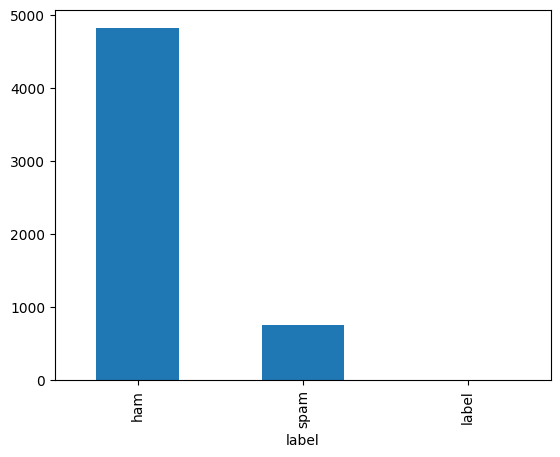

In [64]:
df.label.value_counts().plot(kind='bar')

In [65]:
df.len.describe()

,len
count,5573.000000
mean,80.441414
std,59.938549
min,2.000000
25%,36.000000
50%,61.000000
75%,122.000000
max,910.000000


In [66]:
df[df.len==910].loc[1086,'msg']

"For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later.."

In [67]:
tfidf = TfidfVectorizer(ngram_range=(1,1),analyzer=data_clean)

In [68]:
tfidf1 = tfidf.fit_transform(df.msg)
tfidf1.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5573, 8175))

In [69]:
from sklearn.ensemble import RandomForestClassifier

In [70]:
random_for = RandomForestClassifier(n_estimators=100)
random_for.fit(tfidf1,df.label)

RandomForestClassifier()

* Here label is y_train

In [71]:
y_pred = random_for.predict(tfidf1)

In [74]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,confusion_matrix

In [75]:
accuracy_score(df.label,y_pred)

1.0

* Here we only have y_train from this we can only get training accuracy. that's y we got our training accuracy High 100%.

In [80]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(df.msg,df.label,test_size=0.2,random_state=100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(4458,)
(1115,)
(4458,)
(1115,)


In [81]:
from sklearn.pipeline import Pipeline

In [87]:
pipeline = Pipeline([('tfidf',tfidf),('random_forest',random_for)])
pipeline.fit(x_train,y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer=<function data_clean at 0x785e239287c0>)),
                ('random_forest', RandomForestClassifier())])

In [88]:
y_pred = pipeline.predict(x_test)
accuracy_score(y_test,y_pred)

0.979372197309417

In [89]:
pipeline.predict(["For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later.."])

array(['ham'], dtype=object)

* Here Pipeline is acting as a model.
* It takes the input data and it pass to the Tfidfvectorizer after processing it pass that data to random forest model get trained when we pass x_test it will give us testing accuracy.
* So the accuracy is the data is ham or spam so when we checked with the data in the above cell the text data is belnogs to ham class.